In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.ensemble import IsolationForest

In [2]:
np.random.seed(42)

df = pd.DataFrame({
    "amount": np.random.normal(600, 150, 500),
    "frequency": np.random.normal(8, 2, 500)
})

unusual = pd.DataFrame({
    "amount": np.random.uniform(3000, 6000, 25),
    "frequency": np.random.uniform(30, 60, 25)
})

df = pd.concat([df, unusual], ignore_index=True)

df = df.sample(frac=1, random_state=42).reset_index(drop=True)

df.head()

,amount,frequency
0,567.347820,7.626257
1,465.237799,9.640964
2,836.881922,6.815212
3,566.480582,5.555744
4,613.764116,5.042828


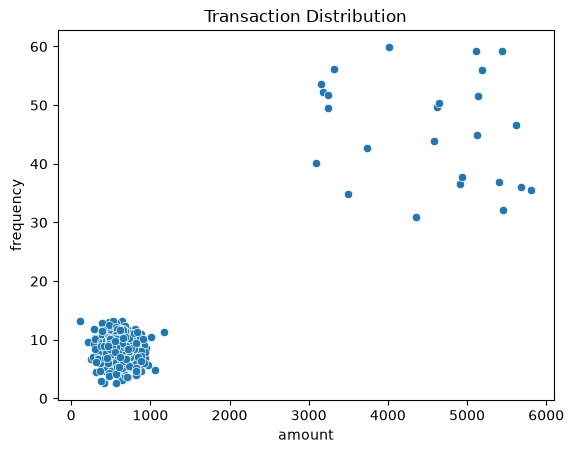

In [3]:
sns.scatterplot(
    data=df,
    x="amount",
    y="frequency"
)

plt.title("Transaction Distribution")
plt.show()

In [4]:
model = IsolationForest(
    n_estimators=100,
    max_samples=256,
    contamination=0.05,
    max_features=1.0,
    bootstrap=False,
    random_state=42
)

model.fit(df)

,"max_samples max_samples: ""auto"", int or float, default=""auto""The number of samples to draw from X to train each base estimator.- If int, then draw `max_samples` samples.- If float, then draw `max_samples * X.shape[0]` samples.- If ""auto"", then `max_samples=min(256, n_samples)`.If max_samples is larger than the number of samples provided,all samples will be used for all trees (no sampling).",256
,"contamination contamination: 'auto' or float, default='auto'The amount of contamination of the data set, i.e. the proportionof outliers in the data set. Used when fitting to define the thresholdon the scores of the samples.- If 'auto', the threshold is determined as in the original paper.- If float, the contamination should be in the range (0, 0.5]... versionchanged:: 0.22 The default value of ``contamination`` changed from 0.1 to ``'auto'``.",0.05
,"random_state random_state: int, RandomState instance or None, default=NoneControls the pseudo-randomness of the selection of the featureand split values for each branching step and each tree in the forest.Pass an int for reproducible results across multiple function calls.See :term:`Glossary <random_state>`.",42
,"n_estimators n_estimators: int, default=100The number of base estimators in the ensemble.",100
,"max_features max_features: int or float, default=1.0The number of features to draw from X to train each base estimator.- If int, then draw `max_features` features.- If float, then draw `max(1, int(max_features * n_features_in_))` features.Note: using a float number less than 1.0 or integer less than number offeatures will enable feature subsampling and leads to a longer runtime.",1.0
,"bootstrap bootstrap: bool, default=FalseIf True, individual trees are fit on random subsets of the trainingdata sampled with replacement. If False, sampling without replacementis performed.",False
,"n_jobs n_jobs: int, default=NoneThe number of jobs to run in parallel for :meth:`fit`. ``None`` means 1unless in a :obj:`joblib.parallel_backend` context. ``-1`` means usingall processors. See :term:`Glossary <n_jobs>` for more details.",None
,"verbose verbose: int, default=0Controls the verbosity of the tree building process.",0
,"warm_start warm_start: bool, default=FalseWhen set to ``True``, reuse the solution of the previous call to fitand add more estimators to the ensemble, otherwise, just fit a wholenew forest. See :term:`the Glossary <warm_start>`... versionadded:: 0.21",False
Name,Type,Value
estimator_ estimator_: :class:`~sklearn.tree.ExtraTreeRegressor` instanceThe child estimator template used to create the collection offitted sub-estimators... versionadded:: 1.2 `base_estimator_` was renamed to `estimator_`.,ExtraTreeRegressor,ExtraTreeRegr...ndom_state=42)


In [5]:
predictions = model.predict(df)

predictions[:10]

array([ 1,  1,  1,  1,  1,  1, -1,  1,  1,  1])

In [7]:
scores = model.score_samples(df)

decision_scores = model.decision_function(df)

In [8]:
df["anomaly_score"] = scores

df["decision_score"] = decision_scores

df["prediction"] = np.where(
    predictions == -1,
    "Anomaly",
    "Normal"
)

df.head()

,amount,frequency,anomaly_score,decision_score,prediction
0,567.347820,7.626257,-0.375648,0.255727,Normal
1,465.237799,9.640964,-0.409920,0.221455,Normal
2,836.881922,6.815212,-0.429093,0.202282,Normal
3,566.480582,5.555744,-0.426526,0.204849,Normal
4,613.764116,5.042828,-0.437081,0.194294,Normal


In [9]:
anomalies = df[df["prediction"] == "Anomaly"]

anomalies.sort_values(
    "anomaly_score"
)

,amount,frequency,anomaly_score,decision_score,prediction
53,5444.475341,59.243795,-0.760319,-0.128944,Anomaly
240,4018.350578,59.890017,-0.757751,-0.126376,Anomaly
210,5119.427179,59.275958,-0.749592,-0.118217,Anomaly
128,5451.893310,32.165952,-0.731497,-0.100122,Anomaly
50,5194.768565,56.048175,-0.728098,-0.096723,Anomaly
457,3502.447747,34.786340,-0.727548,-0.096173,Anomaly
83,4356.954854,30.919575,-0.727287,-0.095912,Anomaly
312,5612.907371,46.660907,-0.726073,-0.094698,Anomaly
166,3313.703521,56.153507,-0.725640,-0.094264,Anomaly
225,5808.636739,35.463537,-0.725582,-0.094207,Anomaly


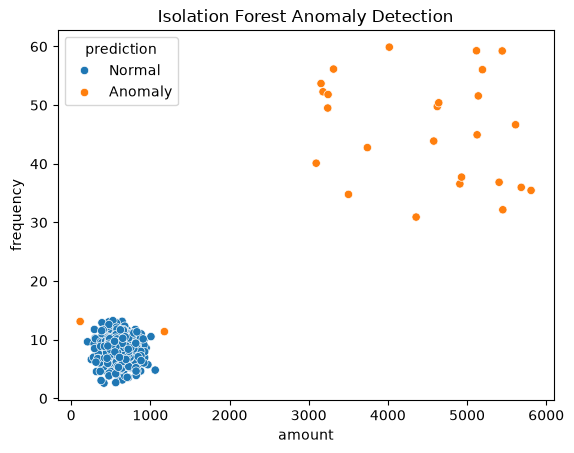

In [10]:
sns.scatterplot(
    data=df,
    x="amount",
    y="frequency",
    hue="prediction"
)

plt.title("Isolation Forest Anomaly Detection")
plt.show()

In [11]:
print("Threshold:", model.offset_)

Threshold: -0.6313750499936501


In [12]:
new_transactions = pd.DataFrame({
    "amount": [500, 700, 4500, 5500, 800],
    "frequency": [7, 9, 45, 55, 6]
})

new_predictions = model.predict(new_transactions)

new_scores = model.score_samples(new_transactions)

new_results = new_transactions.copy()

new_results["anomaly_score"] = new_scores

new_results["prediction"] = np.where(
    new_predictions == -1,
    "Anomaly",
    "Normal"
)

new_results

,amount,frequency,anomaly_score,prediction
0,500,7,-0.380542,Normal
1,700,9,-0.390113,Normal
2,4500,45,-0.698605,Anomaly
3,5500,55,-0.739517,Anomaly
4,800,6,-0.442389,Normal
